In [37]:
import os 
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt 

# modelagem
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.metrics import (roc_curve, log_loss, brier_score_loss, roc_auc_score)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.calibration import calibration_curve
from sklearn.calibration import CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator
from sklearn.base import clone
from sklearn.model_selection import cross_val_score
import joblib
import optuna
import shap
# filtro de warnings 
import warnings
warnings.filterwarnings('ignore')

In [2]:
# funçao para carregar query
def read_load_query(query_path:str):
    con_path = os.path.join('..', 'src', 'analytics', 'CreditDatabase.db')
    con = sqlite3.connect(con_path)
    if not os.path.exists(query_path):
        raise ValueError('query nao encontrada')
    with open(query_path) as f:
        query = f.read()
    return pd.read_sql_query(query, con)

# funçao para contagem de id's duplicados
def duplicated_id(col:pd.DataFrame, id:str):
    data = col.reset_index()
    if not isinstance(col, pd.Series):
        ValueError('Use uma Série válida')
    if isinstance(id, str):
        count = data.duplicated(subset=f'{id}').sum()
        if count >1:
            id_unique = data[id].nunique()
            print('==='*50)
            print(f'Frequencia - Contagem de Id duplicado')
            print('==='*50)
            print()
            print(f"total id's unicos: {id_unique}")
            print(f"contagem id's duplicados: {count}")
        else:
            print('Nenhum id duplicado encontrado')
# funçao de metricas 
def metrics(y_real:pd.Series, y_pred:pd.Series):
    fpr, tpr, _ = roc_curve(y_real, y_pred)
    ks = max(tpr-fpr)
    logLoss = log_loss(y_real, y_pred)
    brier_score = brier_score_loss(y_real, y_pred)
    roc = roc_auc_score(y_real, y_pred)
    gini = 2 * roc - 1
    out = {
        'KS':ks, 
        'LogLoss':logLoss, 
        'Brier_score': brier_score, 
        'ROC_AUC':roc,
        'Gini':gini
    }
    return pd.DataFrame([out])

In [3]:
# query para carregamento da abt 
abt_query = os.path.join('..', 'src', 'analytics', 'abt_query.sql')
df = read_load_query(abt_query)


In [4]:
df.shape

(121966, 41)

In [5]:
df.head()

,id_cliente,id_contrato,safra_decisao,dia_semana_solicitacao,hora_solicitacao,tipo_contrato,valor_credito,valor_bem,valor_parcela,valor_bem_ausente,...,prazo_implicito,valor_bem_maior_que_renda,diff_valor_bem_credito,renda_per_capta,flag_sem_filhos,aposentado,servidor_publico,nota_max_regiao_cliente,periodo_dia,flag_final_de_semana
0,262196,2474552,2017-02,sábado,17,financiamento de consumo,13644.0,15160.5,2163.960,0,...,6.0,0,1516.5,67500.00,1,1,0,0,tarde,0
1,237225,2253903,2017-02,terça-feira,15,Empréstimo em dinheiro,24606.0,26518.5,4938.435,0,...,5.0,0,1912.5,60374.81,0,0,0,0,tarde,0
2,151305,1567829,2017-02,terça-feira,10,financiamento de consumo,34321.5,38137.5,9778.185,0,...,4.0,0,3816.0,67500.00,1,0,0,1,manha,0
3,265591,2448253,2017-02,terça-feira,20,Empréstimo em dinheiro,33228.0,34106.4,3691.620,0,...,9.0,0,878.4,78750.00,1,0,0,0,noite,0
4,318283,2044201,2017-02,terça-feira,10,Empréstimo em dinheiro,14539.5,13855.5,2918.070,0,...,5.0,0,-684.0,69750.00,1,1,0,1,manha,0


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 121966 entries, 0 to 121965
Data columns (total 41 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   id_cliente                  121966 non-null  int64  
 1   id_contrato                 121966 non-null  int64  
 2   safra_decisao               121966 non-null  str    
 3   dia_semana_solicitacao      121966 non-null  str    
 4   hora_solicitacao            121966 non-null  int64  
 5   tipo_contrato               121966 non-null  str    
 6   valor_credito               121966 non-null  float64
 7   valor_bem                   117934 non-null  float64
 8   valor_parcela               121965 non-null  float64
 9   valor_bem_ausente           121966 non-null  int64  
 10  valor_parcela_ausente       121966 non-null  int64  
 11  qtd_filhos                  121966 non-null  int64  
 12  qtd_membros_familia         121966 non-null  float64
 13  renda_anual              

In [7]:
# transformando safra decisao em data e id_cliente em index
df['safra_decisao'] = pd.to_datetime(df['safra_decisao'], errors='coerce', format='%Y-%m')
df = df.set_index(['id_cliente', 'id_contrato','safra_decisao'])


In [8]:
df.head()

,,,dia_semana_solicitacao,hora_solicitacao,tipo_contrato,valor_credito,valor_bem,valor_parcela,valor_bem_ausente,valor_parcela_ausente,qtd_filhos,qtd_membros_familia,...,prazo_implicito,valor_bem_maior_que_renda,diff_valor_bem_credito,renda_per_capta,flag_sem_filhos,aposentado,servidor_publico,nota_max_regiao_cliente,periodo_dia,flag_final_de_semana
id_cliente,id_contrato,safra_decisao,,,,,,,,,,,,,,,,,,,,,
262196,2474552,2017-02-01,sábado,17,financiamento de consumo,13644.0,15160.5,2163.960,0,0,0,2.0,...,6.0,0,1516.5,67500.00,1,1,0,0,tarde,0
237225,2253903,2017-02-01,terça-feira,15,Empréstimo em dinheiro,24606.0,26518.5,4938.435,0,0,2,4.0,...,5.0,0,1912.5,60374.81,0,0,0,0,tarde,0
151305,1567829,2017-02-01,terça-feira,10,financiamento de consumo,34321.5,38137.5,9778.185,0,0,0,2.0,...,4.0,0,3816.0,67500.00,1,0,0,1,manha,0
265591,2448253,2017-02-01,terça-feira,20,Empréstimo em dinheiro,33228.0,34106.4,3691.620,0,0,0,2.0,...,9.0,0,878.4,78750.00,1,0,0,0,noite,0
318283,2044201,2017-02-01,terça-feira,10,Empréstimo em dinheiro,14539.5,13855.5,2918.070,0,0,0,2.0,...,5.0,0,-684.0,69750.00,1,1,0,1,manha,0


In [9]:
# event rate 
event_rate = df['TARGET'].mean()
print(f'Taxa de inadimplência: {event_rate*100}%')

Taxa de inadimplência: 14.048177360903857%


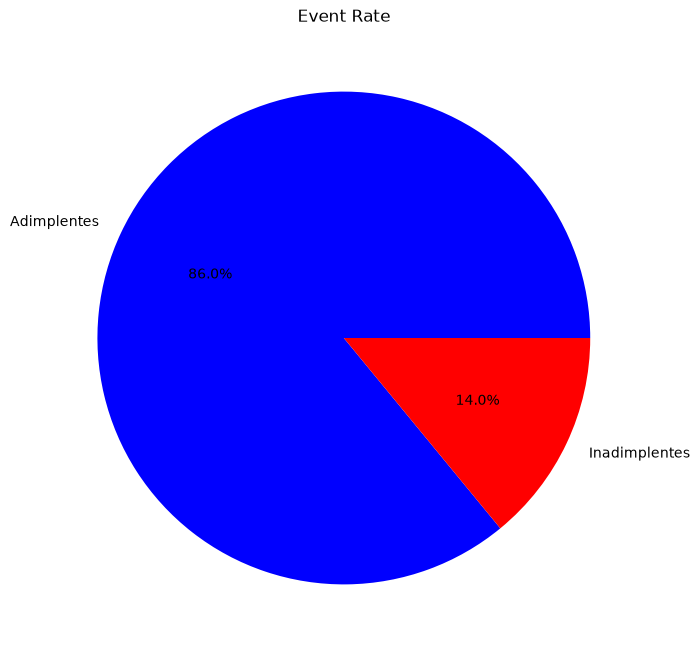

In [10]:
plt.figure(figsize=(12,8))
plt.title('Event Rate')
plt.pie(df['TARGET'].value_counts(), labels=['Adimplentes', 'Inadimplentes'], colors=['blue', 'red'],autopct='%1.1f%%')

In [11]:
duplicated_id(df, 'id_cliente')

Frequencia - Contagem de Id duplicado

total id's unicos: 45916
contagem id's duplicados: 76050


In [12]:
duplicated_id(df, 'id_contrato')

Nenhum id duplicado encontrado


- Os id_cliente duplicados referem-se aos cliente que realizam pedidos de emprestimos mais de uma vez, porém, em contratos diferentes

- Não irei fazer teste de multicoliaridade, pois os modelos que irei utilizar são baseados em arvores: XGBoost, LGBM e CatBoost 


# Separação Treino-Teste

In [13]:
X = df.drop('TARGET', axis=1)
y = df['TARGET']
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, shuffle=True, stratify=y)
# validaçao 
X_t, X_val, y_t, y_val = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train, shuffle=True)

In [14]:
cat_cols = df.select_dtypes(exclude='number').columns
cat_cols

Index(['dia_semana_solicitacao', 'tipo_contrato', 'tipo_renda', 'ocupacao',
       'tipo_organizacao', 'nivel_educacao', 'estado_civil', 'tipo_moradia',
       'possui_carro', 'possui_imovel', 'periodo_dia'],
      dtype='str')

In [15]:
# definindo modelos 
models = {
    'XGBoost':XGBClassifier(random_state=42),
    'LGBM':LGBMClassifier(random_state=42, class_weight='balanced'),
    'CatBoost':CatBoostClassifier(random_state=42, cat_features=list(cat_cols), verbose=0, iterations=1000, auto_class_weights='Balanced')
}

In [16]:
# pipeline 
column_transf = ColumnTransformer([('onehot', OneHotEncoder(handle_unknown='ignore'), cat_cols)])
pipe = Pipeline(steps=[('prepross', column_transf),
                        ('model', XGBClassifier(random_state=42))])

In [17]:
pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prepross', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('onehot', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the 

Treinando modelo: XGBoost
métricas de treino:
         KS   LogLoss  Brier_score   ROC_AUC      Gini
0  0.379735  0.342271     0.100987  0.761155  0.522309
métricas de validaçao
        KS   LogLoss  Brier_score   ROC_AUC      Gini
0  0.31132  0.364237     0.106829  0.693905  0.387809

Treinando modelo: LGBM
[LightGBM] [Info] Number of positive: 13707, number of negative: 83865
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.007525 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 236
[LightGBM] [Info] Number of data points in the train set: 97572, number of used features: 118
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
métricas de treino:
         KS   LogLoss  Brier_score   ROC_AUC      Gini
0  0.344806  0.594284      0.20055  0.735896  0.471793
mé

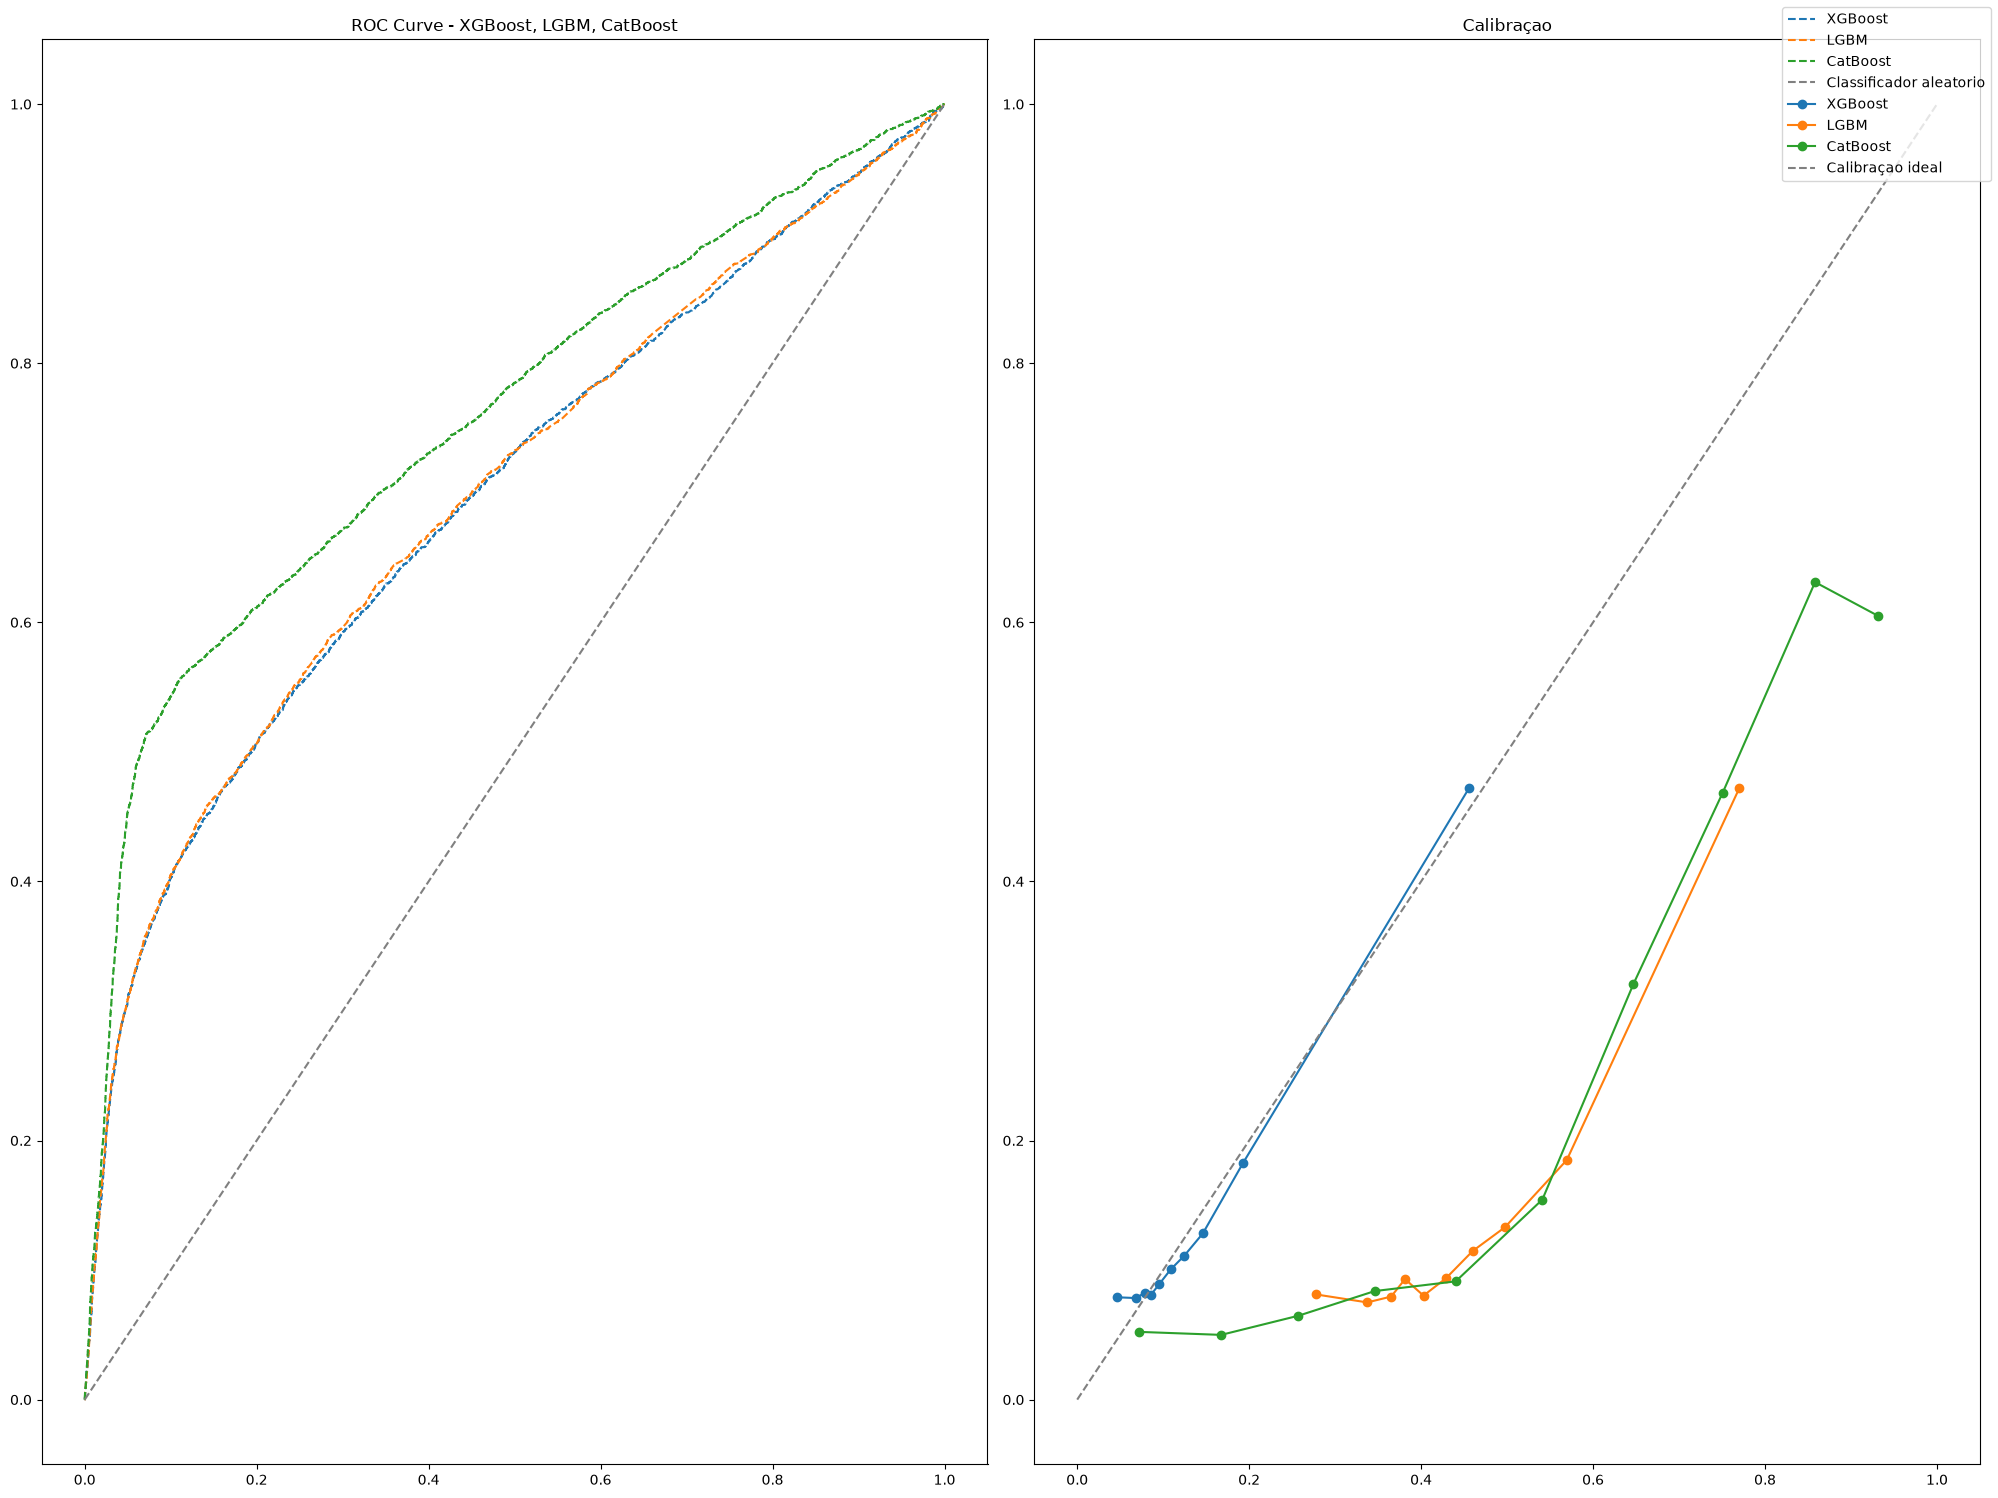

In [18]:
#treinamento dos modelos
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(20,15))
for i, model in models.items():
    if i == 'CatBoost':
        print(f'Treinando modelo: {i}')
        model_train = model.fit(X_train, y_train)
        pred_train = model_train.predict_proba(X_train)[:,1]
        pred_valid = model_train.predict_proba(X_test)[:,1]
        prob_true, prob_pred = calibration_curve(y_test,pred_valid, n_bins=10)
        print('métricas de treino:')
        print(metrics(y_train, pred_train))
        print('métricas de validaçao')
        print(metrics(y_test, pred_valid))
        print()
    else: 
        print(f'Treinando modelo: {i}')
        model_train = pipe.set_params(model=model).fit(X_train, y_train)
        pred_train = model_train.predict_proba(X_train)[:,1]
        pred_valid = model_train.predict_proba(X_test)[:,1]
        prob_true, prob_pred = calibration_curve(y_test,pred_valid, n_bins=10, strategy='quantile')
        print('métricas de treino:')
        print(metrics(y_train, pred_train))
        print('métricas de validaçao')
        print(metrics(y_test, pred_valid))
        print()
    fpr, tpr, _ = roc_curve(y_test, pred_valid)
    axes[0].plot(fpr, tpr, linestyle='--', label=f'{i}')
    axes[1].plot(prob_pred, prob_true, marker='o', label=f'{i}')
axes[0].plot([0, 1], [0, 1], linestyle='--', color='gray', label='Classificador aleatorio')
axes[1].plot([0, 1], [0, 1], linestyle='--', color='gray', label='Calibraçao ideal')
axes[0].set_title('ROC Curve - XGBoost, LGBM, CatBoost')
axes[1].set_title('Calibraçao')
fig.legend()
fig.tight_layout()
fig.show()

# Calibração dos modelos 

calibrando modelo XGBoost
         KS   LogLoss  Brier_score   ROC_AUC      Gini
0  0.318251  0.360671      0.10596  0.696549  0.393099
calibrando modelo LGBM
[LightGBM] [Info] Number of positive: 10965, number of negative: 67092
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.005130 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 234
[LightGBM] [Info] Number of data points in the train set: 78057, number of used features: 117
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
[LightGBM] [Info] Number of positive: 10965, number of negative: 67092
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004021 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_co

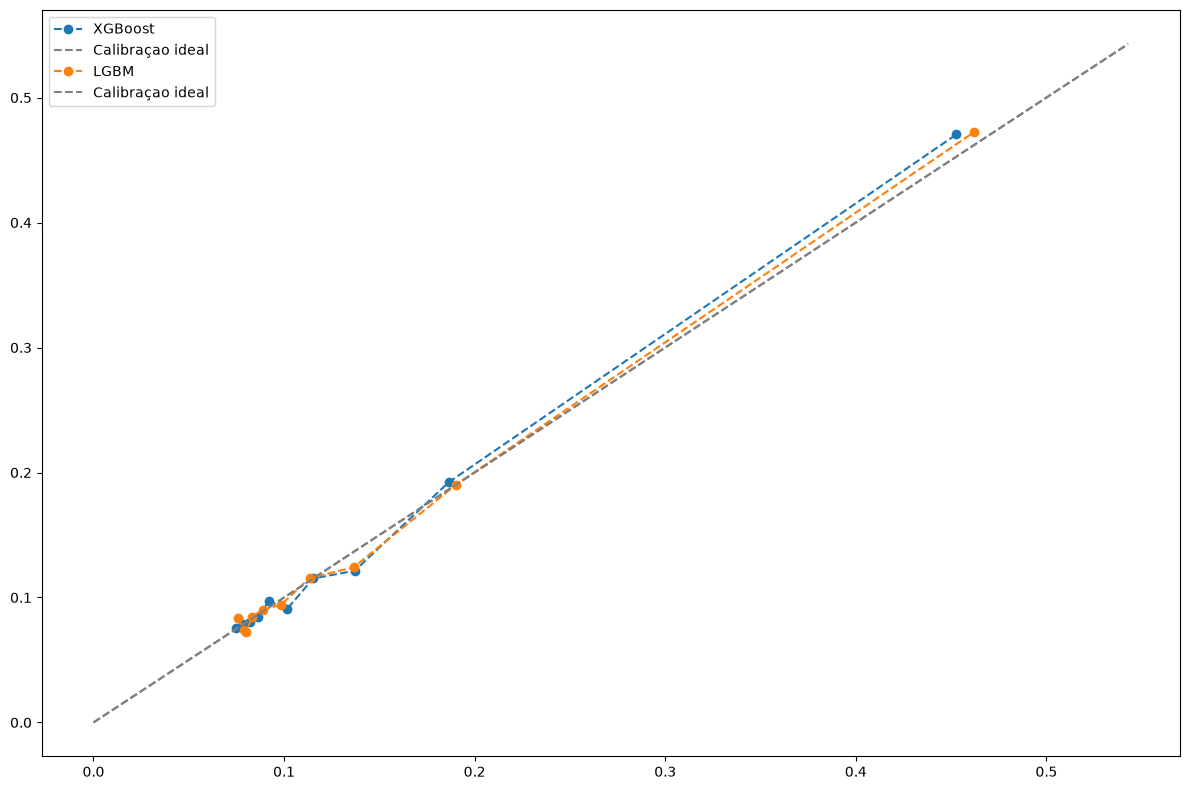

In [19]:
# calibrando XGBoost e LGBM
results = {}
plt.figure(figsize=(12,8))
for i, calibration in models.items():
    if i !='CatBoost':
        print(f'calibrando modelo {i}')
        model = clone(pipe).set_params(model=calibration)
        calibrated_model = CalibratedClassifierCV(estimator=model, method='isotonic', cv=5)
        calibrated_model.fit(X_train, y_train)
        prob = calibrated_model.predict_proba(X_test)[:,1]
        print(metrics(y_test, prob))
        prob_true, prob_pred = calibration_curve(y_test, prob, n_bins=10, strategy='quantile')
        results[i] = {
        'modelo': calibrated_model,
        'prob_calibrada': prob,
        'prob_true': prob_true,
        'prob_pred': prob_pred
            }
        lim = max(prob_pred.max(), prob_true.max()) * 1.15
        plt.plot(prob_pred, prob_true, label=i, linestyle='--', marker='o')
        plt.plot([0, lim], [0, lim], linestyle='--', color='gray', label='Calibraçao ideal')
        
plt.tight_layout()
plt.legend()
plt.show()


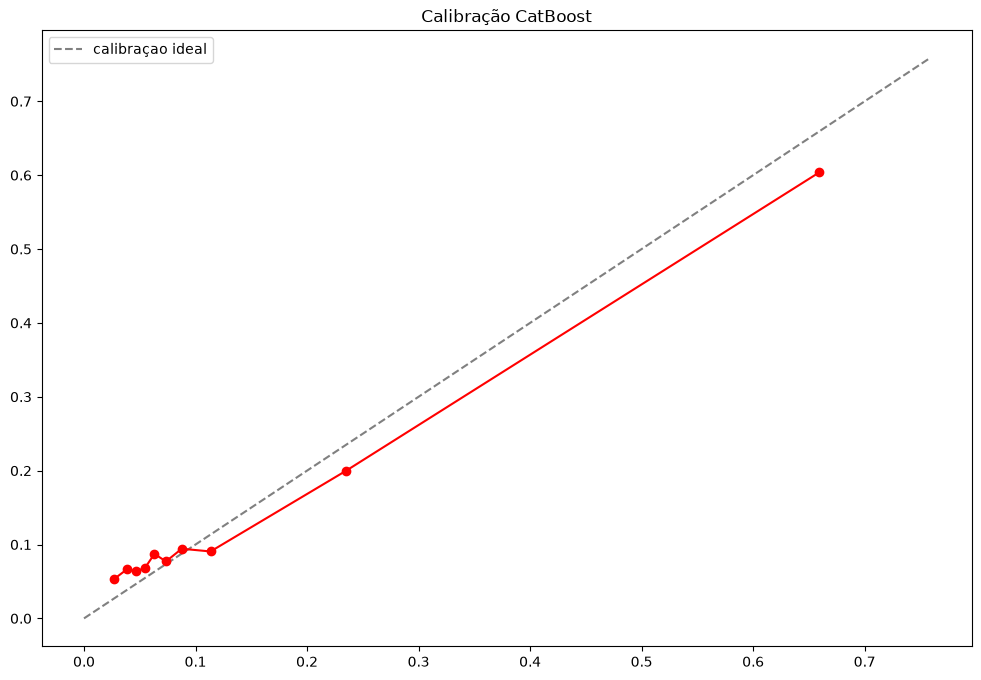

In [20]:
# calibrando catboost 
catboost = CatBoostClassifier(random_state=42,verbose=0, iterations=1000, auto_class_weights='Balanced').fit(X_train, y_train, cat_features=list(cat_cols))
prob_pred = catboost.predict_proba(X_test)[:,1]
calibrated_model = CalibratedClassifierCV(FrozenEstimator(catboost), method='sigmoid', cv=5)
calibrated_model.fit(X_train, y_train)
prob = calibrated_model.predict_proba(X_test)[:,1]
prob_true, prob_pred = calibration_curve(y_test, prob, n_bins=10, strategy='quantile')

# plotando curva de calibraçao 
plt.figure(figsize=(12,8))
plt.title('Calibração CatBoost')
lim = max(prob_pred.max(), prob_true.max()) * 1.15
plt.plot([0,lim],[0,lim], linestyle='--', color='gray', label='calibraçao ideal')
plt.plot(prob_pred, prob_true, marker='o', color='red')
plt.legend()
plt.show()

In [21]:
prob1_catboost = calibrated_model.predict_proba(X_test)[:,1]
prob2_catboost = catboost.predict_proba(X_test)[:,1]
display(metrics(y_test, prob1_catboost))
display(metrics(y_test, prob2_catboost))

,KS,LogLoss,Brier_score,ROC_AUC,Gini
0,0.446007,0.330671,0.09503,0.75587,0.511739


,KS,LogLoss,Brier_score,ROC_AUC,Gini
0,0.446007,0.519317,0.162579,0.75587,0.511739


Por métricas, o CatBoost apresentou valores melhores que os demais. Porem, em calibraçao, XGBoost e LGBM apresentaram comportamentos melhores

Pela performance e por boa calibração de probabilidades, seguirei avaliando o XGBoost

In [22]:
# setando Xgboost
Xgboost = pipe.set_params(model=XGBClassifier())
Xgboost.fit(X_train, y_train)
# calibrando 
Xgboost_cal = CalibratedClassifierCV(estimator=Xgboost, method='isotonic', cv=10).fit(X_train, y_train)

# Cross-Validation

Validação cruzada para 10 folds

In [23]:
cross_val = cross_val_score(Xgboost_cal, X,y, cv=10, scoring='f1_macro')
print(f'scores:', cross_val)
print('Min:', cross_val.min())
print('Max:', cross_val.max())
print('Média:', cross_val.mean())

scores: [0.56457222 0.63176036 0.64813104 0.64219185 0.66676385 0.64401895
 0.63318565 0.6097253  0.59348103 0.56286388]
Min: 0.5628638840694465
Max: 0.666763850057084
Média: 0.6196694119616681


# Fazendo previsões

In [24]:
# carregando bases
data_pred = os.path.join('..', 'data', 'processed', 'base_submissao_tratada.parquet')
df_pred = pd.read_parquet(data_pred)
df_pred.head()

,,dia_semana_solicitacao,hora_solicitacao,tipo_contrato,valor_credito,valor_bem,valor_parcela,valor_bem_ausente,valor_parcela_ausente,qtd_filhos,qtd_membros_familia,...,prazo_implicito,valor_bem_maior_que_renda,diff_valor_bem_credito,renda_per_capta,flag_sem_filhos,aposentado,servidor_publico,nota_max_regiao_cliente,periodo_dia,flag_final_de_semana
id_cliente,data_solicitacao,,,,,,,,,,,,,,,,,,,,,
100023,2025-02-24,segunda-feira,12.0,financiamento de consumo,544491.0,454500.0,17563.5,0,0,1,2.0,...,31.00,1,-89991.0,45000.0,0,0,0,0,tarde,0
100031,2025-02-17,segunda-feira,9.0,crédito rotativo,979992.0,702000.0,27076.5,0,0,0,1.0,...,36.19,1,-277992.0,112500.0,1,0,0,1,manha,0
100056,2025-02-20,quinta-feira,10.0,empréstimo em dinheiro,1506816.0,1350000.0,49927.5,0,0,0,2.0,...,30.18,1,-156816.0,180000.0,1,0,0,0,manha,0
100069,2025-02-10,segunda-feira,11.0,empréstimo em dinheiro,640458.0,517500.0,27265.5,0,0,1,2.0,...,23.49,1,-122958.0,180000.0,0,0,0,0,manha,0
100085,2025-02-19,quarta-feira,12.0,empréstimo em dinheiro,755190.0,675000.0,28894.5,0,0,1,3.0,...,26.14,1,-80190.0,-5891.0,0,0,0,0,tarde,0


In [25]:
df_submission = pd.DataFrame()
df_submission['id_cliente'] = df_pred.reset_index()['id_cliente']
df_submission['data_solicitacao'] = df_pred.reset_index()['data_solicitacao']

In [26]:
df_submission['probabilidade'] = Xgboost_cal.predict_proba(df_pred)[:,1]

In [27]:
df_submission

,id_cliente,data_solicitacao,probabilidade
0,100023,2025-02-24,0.100792
1,100031,2025-02-17,0.078942
2,100056,2025-02-20,0.077723
3,100069,2025-02-10,0.076397
4,100085,2025-02-19,0.094438
...,...,...,...
51000,416566,2025-02-18,0.106597
51001,265132,2025-02-22,0.145926
51002,344181,2025-02-18,0.083780
51003,410444,2025-02-14,0.133491


# Separação de Grupos Homogêneos

de 0% a 10% -> Risco Baixo

de 10% a 17% -> Risco Médio

de 17% a 100% -> Risco Alto

In [28]:
# fazendo uso do pd.qcut para separaçao de grupos de risco 
labels = ['BAIXO', 'MÉDIO', 'ALTO']
risk_groups = pd.qcut(df_submission['probabilidade'],q=3, labels=labels)
df_submission['RISCO'] = risk_groups

In [29]:
df_submission['RISCO'].value_counts(normalize=True)

RISCO
BAIXO    0.33334
MÉDIO    0.33334
ALTO     0.33332
Name: proportion, dtype: float64

In [30]:
df_submission.head()

,id_cliente,data_solicitacao,probabilidade,RISCO
0,100023,2025-02-24,0.100792,MÉDIO
1,100031,2025-02-17,0.078942,BAIXO
2,100056,2025-02-20,0.077723,BAIXO
3,100069,2025-02-10,0.076397,BAIXO
4,100085,2025-02-19,0.094438,BAIXO


# Otimização de hyperparametros - Optuna

Farei uso do optuna para busca bayesiana de hyperparamentros

In [31]:
# funçao objetivo 
def objective(trial):
    params = {
        'max_depth': trial.suggest_int('max_depth', 3, 10),                     
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True), 
        'n_estimators': trial.suggest_int('n_estimators', 300, 1500),           
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),                
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),  
        'gamma': trial.suggest_float('gamma', 0, 5),                            
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-4, 10, log=True),                   
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 20.0, log=True),                
        'min_child_weight': trial.suggest_int('min_child_weight',  1.0, 20.0, log=True),       
        'max_delta_step': trial.suggest_int('max_delta_step', 0, 5),           
        'random_state': 42,
        'n_jobs': -1,
        'eval_metric': 'auc'

        }
    model = pipe.set_params(model=XGBClassifier(**params)).fit(X_train, y_train)
    y_pred = model.predict_proba(X_test)[:,1]
    error  = brier_score_loss(y_test, y_pred)
    return error
study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=50, show_progress_bar=True)

[I 2026-10-26 18:53:31,117] A new study created in memory with name: no-name-2c34dc0c-b5ab-4004-80cc-d0c13112b0ad
Best trial: 0. Best value: 0.10629:   2%|▏         | 1/50 [00:05<04:13,  5.17s/it]

[I 2026-10-26 18:53:36,291] Trial 0 finished with value: 0.10629034787416458 and parameters: {'max_depth': 10, 'learning_rate': 0.025657305570694657, 'n_estimators': 574, 'subsample': 0.7018963855552095, 'colsample_bytree': 0.9074057730282951, 'gamma': 0.6350439679767089, 'reg_alpha': 0.00022429366830426412, 'reg_lambda': 3.245270591111899, 'min_child_weight': 4, 'max_delta_step': 2}. Best is trial 0 with value: 0.10629034787416458.


Best trial: 0. Best value: 0.10629:   4%|▍         | 2/50 [00:09<03:30,  4.38s/it]

[I 2026-10-26 18:53:40,123] Trial 1 finished with value: 0.10689900815486908 and parameters: {'max_depth': 7, 'learning_rate': 0.013323143292611632, 'n_estimators': 627, 'subsample': 0.9846095991359399, 'colsample_bytree': 0.6313898866201372, 'gamma': 1.4720838731176218, 'reg_alpha': 0.877755738865666, 'reg_lambda': 0.11784914636756219, 'min_child_weight': 15, 'max_delta_step': 3}. Best is trial 0 with value: 0.10629034787416458.


Best trial: 0. Best value: 0.10629:   6%|▌         | 3/50 [00:14<03:41,  4.72s/it]

[I 2026-10-26 18:53:45,245] Trial 2 finished with value: 0.1064293384552002 and parameters: {'max_depth': 6, 'learning_rate': 0.09509641857728618, 'n_estimators': 1301, 'subsample': 0.7150421181421858, 'colsample_bytree': 0.9887301373220563, 'gamma': 3.1123890382285846, 'reg_alpha': 0.00033990290780228755, 'reg_lambda': 0.00982628573885969, 'min_child_weight': 13, 'max_delta_step': 2}. Best is trial 0 with value: 0.10629034787416458.


Best trial: 0. Best value: 0.10629:   8%|▊         | 4/50 [00:17<03:12,  4.19s/it]

[I 2026-10-26 18:53:48,626] Trial 3 finished with value: 0.10683537274599075 and parameters: {'max_depth': 8, 'learning_rate': 0.014969953337281535, 'n_estimators': 423, 'subsample': 0.7785301613945166, 'colsample_bytree': 0.6015160301510571, 'gamma': 1.6710521230969437, 'reg_alpha': 0.25382118876233084, 'reg_lambda': 0.6486575911440239, 'min_child_weight': 2, 'max_delta_step': 2}. Best is trial 0 with value: 0.10629034787416458.


Best trial: 0. Best value: 0.10629:  10%|█         | 5/50 [00:21<03:09,  4.20s/it]

[I 2026-10-26 18:53:52,853] Trial 4 finished with value: 0.1074884906411171 and parameters: {'max_depth': 3, 'learning_rate': 0.037856541984466835, 'n_estimators': 1017, 'subsample': 0.8247302148802705, 'colsample_bytree': 0.602213069266379, 'gamma': 3.2570269612904306, 'reg_alpha': 0.0016633305600864691, 'reg_lambda': 0.0029498511682260566, 'min_child_weight': 7, 'max_delta_step': 3}. Best is trial 0 with value: 0.10629034787416458.


Best trial: 0. Best value: 0.10629:  12%|█▏        | 6/50 [00:23<02:32,  3.46s/it]

[I 2026-10-26 18:53:54,870] Trial 5 finished with value: 0.107276052236557 and parameters: {'max_depth': 6, 'learning_rate': 0.04253705921560784, 'n_estimators': 322, 'subsample': 0.930651702687725, 'colsample_bytree': 0.8005063817944192, 'gamma': 4.645783341697963, 'reg_alpha': 0.7569735982053384, 'reg_lambda': 3.6711395749513334, 'min_child_weight': 2, 'max_delta_step': 3}. Best is trial 0 with value: 0.10629034787416458.


Best trial: 0. Best value: 0.10629:  14%|█▍        | 7/50 [00:27<02:35,  3.62s/it]

[I 2026-10-26 18:53:58,821] Trial 6 finished with value: 0.10630221664905548 and parameters: {'max_depth': 6, 'learning_rate': 0.1723424093786001, 'n_estimators': 921, 'subsample': 0.7532577202166627, 'colsample_bytree': 0.8008967655902856, 'gamma': 2.396010185419228, 'reg_alpha': 0.2774747914120275, 'reg_lambda': 0.017911832886398724, 'min_child_weight': 9, 'max_delta_step': 1}. Best is trial 0 with value: 0.10629034787416458.


Best trial: 0. Best value: 0.10629:  16%|█▌        | 8/50 [00:31<02:30,  3.57s/it]

[I 2026-10-26 18:54:02,294] Trial 7 finished with value: 0.10698605328798294 and parameters: {'max_depth': 3, 'learning_rate': 0.13255563510179988, 'n_estimators': 752, 'subsample': 0.7390228044012409, 'colsample_bytree': 0.8749060146606016, 'gamma': 3.5623479759714, 'reg_alpha': 0.0170942834219337, 'reg_lambda': 0.003203218360905661, 'min_child_weight': 7, 'max_delta_step': 0}. Best is trial 0 with value: 0.10629034787416458.


Best trial: 0. Best value: 0.10629:  18%|█▊        | 9/50 [00:34<02:25,  3.54s/it]

[I 2026-10-26 18:54:05,758] Trial 8 finished with value: 0.1080051064491272 and parameters: {'max_depth': 4, 'learning_rate': 0.014160009203055083, 'n_estimators': 677, 'subsample': 0.8464318445529241, 'colsample_bytree': 0.9551551370647386, 'gamma': 3.0376663583566508, 'reg_alpha': 0.08371302657992824, 'reg_lambda': 0.05481618026112848, 'min_child_weight': 4, 'max_delta_step': 0}. Best is trial 0 with value: 0.10629034787416458.


Best trial: 0. Best value: 0.10629:  20%|██        | 10/50 [00:38<02:30,  3.75s/it]

[I 2026-10-26 18:54:09,991] Trial 9 finished with value: 0.10657686740159988 and parameters: {'max_depth': 7, 'learning_rate': 0.022668299449149103, 'n_estimators': 872, 'subsample': 0.8933491453965967, 'colsample_bytree': 0.8349305781723358, 'gamma': 3.0438350441149433, 'reg_alpha': 0.020964708626103907, 'reg_lambda': 3.3687818102318943, 'min_child_weight': 2, 'max_delta_step': 4}. Best is trial 0 with value: 0.10629034787416458.


Best trial: 0. Best value: 0.10629:  22%|██▏       | 11/50 [00:42<02:20,  3.60s/it]

[I 2026-10-26 18:54:13,258] Trial 10 finished with value: 0.10656004399061203 and parameters: {'max_depth': 10, 'learning_rate': 0.018395258441973403, 'n_estimators': 327, 'subsample': 0.6379004661722268, 'colsample_bytree': 0.812136363623257, 'gamma': 0.8656578008090403, 'reg_alpha': 0.0008362256818692986, 'reg_lambda': 0.0858222250210332, 'min_child_weight': 14, 'max_delta_step': 3}. Best is trial 0 with value: 0.10629034787416458.


Best trial: 0. Best value: 0.10629:  24%|██▍       | 12/50 [00:45<02:15,  3.57s/it]

[I 2026-10-26 18:54:16,755] Trial 11 finished with value: 0.10638734698295593 and parameters: {'max_depth': 7, 'learning_rate': 0.09178696280430942, 'n_estimators': 814, 'subsample': 0.8342719703067322, 'colsample_bytree': 0.8508179584146747, 'gamma': 2.5207351812768573, 'reg_alpha': 0.0009106835298371315, 'reg_lambda': 0.15959702225524872, 'min_child_weight': 11, 'max_delta_step': 1}. Best is trial 0 with value: 0.10629034787416458.


Best trial: 0. Best value: 0.10629:  26%|██▌       | 13/50 [00:51<02:34,  4.18s/it]

[I 2026-10-26 18:54:22,330] Trial 12 finished with value: 0.10634052753448486 and parameters: {'max_depth': 9, 'learning_rate': 0.024258911982206935, 'n_estimators': 689, 'subsample': 0.7789569249520857, 'colsample_bytree': 0.9879993882316099, 'gamma': 0.2569526091819381, 'reg_alpha': 0.011698103265350942, 'reg_lambda': 5.37616620504232, 'min_child_weight': 4, 'max_delta_step': 2}. Best is trial 0 with value: 0.10629034787416458.


Best trial: 0. Best value: 0.10629:  28%|██▊       | 14/50 [00:54<02:22,  3.95s/it]

[I 2026-10-26 18:54:25,754] Trial 13 finished with value: 0.1068030297756195 and parameters: {'max_depth': 10, 'learning_rate': 0.011221429801436943, 'n_estimators': 366, 'subsample': 0.6554399202111885, 'colsample_bytree': 0.9657703605835164, 'gamma': 2.4885937379612306, 'reg_alpha': 0.00015152593721356672, 'reg_lambda': 3.582410776637962, 'min_child_weight': 2, 'max_delta_step': 1}. Best is trial 0 with value: 0.10629034787416458.


Best trial: 0. Best value: 0.10629:  30%|███       | 15/50 [00:57<02:07,  3.65s/it]

[I 2026-10-26 18:54:28,716] Trial 14 finished with value: 0.10629654675722122 and parameters: {'max_depth': 7, 'learning_rate': 0.06977950696450504, 'n_estimators': 451, 'subsample': 0.6965084938106925, 'colsample_bytree': 0.7644603517254216, 'gamma': 1.9555590420148032, 'reg_alpha': 0.0012867730926019727, 'reg_lambda': 0.018573454721345653, 'min_child_weight': 13, 'max_delta_step': 1}. Best is trial 0 with value: 0.10629034787416458.


Best trial: 0. Best value: 0.10629:  32%|███▏      | 16/50 [01:02<02:12,  3.91s/it]

[I 2026-10-26 18:54:33,210] Trial 15 finished with value: 0.10631557554006577 and parameters: {'max_depth': 10, 'learning_rate': 0.014088034287497322, 'n_estimators': 499, 'subsample': 0.6667145874310665, 'colsample_bytree': 0.9179089598993073, 'gamma': 0.5615556990190111, 'reg_alpha': 0.0001388713316946636, 'reg_lambda': 2.713555605623964, 'min_child_weight': 6, 'max_delta_step': 1}. Best is trial 0 with value: 0.10629034787416458.


Best trial: 0. Best value: 0.10629:  34%|███▍      | 17/50 [01:05<02:07,  3.88s/it]

[I 2026-10-26 18:54:37,024] Trial 16 finished with value: 0.10657122731208801 and parameters: {'max_depth': 8, 'learning_rate': 0.04846901493506368, 'n_estimators': 474, 'subsample': 0.76167364997429, 'colsample_bytree': 0.8961186604277935, 'gamma': 0.3015202422918877, 'reg_alpha': 0.0003162179492956768, 'reg_lambda': 0.472154238910288, 'min_child_weight': 4, 'max_delta_step': 3}. Best is trial 0 with value: 0.10629034787416458.


Best trial: 0. Best value: 0.10629:  36%|███▌      | 18/50 [01:13<02:39,  5.00s/it]

[I 2026-10-26 18:54:44,623] Trial 17 finished with value: 0.10653543472290039 and parameters: {'max_depth': 10, 'learning_rate': 0.03184379993499851, 'n_estimators': 860, 'subsample': 0.6127157539365419, 'colsample_bytree': 0.8452497775751239, 'gamma': 0.8460614602700917, 'reg_alpha': 0.00014791828025351444, 'reg_lambda': 15.694911090677424, 'min_child_weight': 2, 'max_delta_step': 1}. Best is trial 0 with value: 0.10629034787416458.


Best trial: 0. Best value: 0.10629:  38%|███▊      | 19/50 [01:16<02:14,  4.32s/it]

[I 2026-10-26 18:54:47,383] Trial 18 finished with value: 0.10630130767822266 and parameters: {'max_depth': 7, 'learning_rate': 0.04764730385817551, 'n_estimators': 396, 'subsample': 0.663894329580067, 'colsample_bytree': 0.8118425542109673, 'gamma': 2.4053538474064533, 'reg_alpha': 0.0022906532792136575, 'reg_lambda': 0.17053607040363905, 'min_child_weight': 5, 'max_delta_step': 1}. Best is trial 0 with value: 0.10629034787416458.


Best trial: 19. Best value: 0.106262:  40%|████      | 20/50 [01:19<02:01,  4.05s/it]

[I 2026-10-26 18:54:50,785] Trial 19 finished with value: 0.10626249015331268 and parameters: {'max_depth': 7, 'learning_rate': 0.07200094348957997, 'n_estimators': 593, 'subsample': 0.7186794373872823, 'colsample_bytree': 0.8286449408379988, 'gamma': 1.9788613661269694, 'reg_alpha': 0.00022919247094500838, 'reg_lambda': 2.9082799881430526, 'min_child_weight': 8, 'max_delta_step': 1}. Best is trial 19 with value: 0.10626249015331268.


Best trial: 19. Best value: 0.106262:  42%|████▏     | 21/50 [01:23<01:54,  3.94s/it]

[I 2026-10-26 18:54:54,462] Trial 20 finished with value: 0.10653577744960785 and parameters: {'max_depth': 10, 'learning_rate': 0.012920821523042018, 'n_estimators': 400, 'subsample': 0.6997030112252914, 'colsample_bytree': 0.9233861932559992, 'gamma': 1.5202229571936545, 'reg_alpha': 0.005967255975327272, 'reg_lambda': 5.234823506828815, 'min_child_weight': 3, 'max_delta_step': 1}. Best is trial 19 with value: 0.10626249015331268.


Best trial: 19. Best value: 0.106262:  44%|████▍     | 22/50 [01:26<01:46,  3.82s/it]

[I 2026-10-26 18:54:58,013] Trial 21 finished with value: 0.10631604492664337 and parameters: {'max_depth': 10, 'learning_rate': 0.06552678748623093, 'n_estimators': 588, 'subsample': 0.6846784325266494, 'colsample_bytree': 0.7921511562250731, 'gamma': 1.856744496094638, 'reg_alpha': 0.0004910709992625555, 'reg_lambda': 7.1271097419824905, 'min_child_weight': 13, 'max_delta_step': 2}. Best is trial 19 with value: 0.10626249015331268.


Best trial: 22. Best value: 0.106091:  46%|████▌     | 23/50 [01:32<01:54,  4.23s/it]

[I 2026-10-26 18:55:03,186] Trial 22 finished with value: 0.10609062016010284 and parameters: {'max_depth': 10, 'learning_rate': 0.026622576589825756, 'n_estimators': 773, 'subsample': 0.6907408310957603, 'colsample_bytree': 0.9030159541075617, 'gamma': 1.6549014814538867, 'reg_alpha': 0.0005512390701436244, 'reg_lambda': 9.596831088785313, 'min_child_weight': 3, 'max_delta_step': 3}. Best is trial 22 with value: 0.10609062016010284.


Best trial: 22. Best value: 0.106091:  48%|████▊     | 24/50 [01:36<01:55,  4.43s/it]

[I 2026-10-26 18:55:08,080] Trial 23 finished with value: 0.10622726380825043 and parameters: {'max_depth': 9, 'learning_rate': 0.018147871107276482, 'n_estimators': 789, 'subsample': 0.6660307636842699, 'colsample_bytree': 0.8966765525037937, 'gamma': 2.3012531918444146, 'reg_alpha': 0.00017745186183305018, 'reg_lambda': 7.977009024678511, 'min_child_weight': 6, 'max_delta_step': 3}. Best is trial 22 with value: 0.10609062016010284.


Best trial: 22. Best value: 0.106091:  50%|█████     | 25/50 [01:42<01:56,  4.67s/it]

[I 2026-10-26 18:55:13,314] Trial 24 finished with value: 0.10618510097265244 and parameters: {'max_depth': 8, 'learning_rate': 0.0182739370730889, 'n_estimators': 803, 'subsample': 0.6498298860426428, 'colsample_bytree': 0.7790290527431543, 'gamma': 1.9765045096085663, 'reg_alpha': 0.00016993960167766247, 'reg_lambda': 1.6929556855791166, 'min_child_weight': 4, 'max_delta_step': 3}. Best is trial 22 with value: 0.10609062016010284.


Best trial: 22. Best value: 0.106091:  52%|█████▏    | 26/50 [01:49<02:07,  5.32s/it]

[I 2026-10-26 18:55:20,144] Trial 25 finished with value: 0.10618113726377487 and parameters: {'max_depth': 10, 'learning_rate': 0.011476904899258143, 'n_estimators': 1027, 'subsample': 0.6174438567820645, 'colsample_bytree': 0.7695405648618533, 'gamma': 2.290814530817008, 'reg_alpha': 0.00018621293736107447, 'reg_lambda': 4.127632499471917, 'min_child_weight': 4, 'max_delta_step': 4}. Best is trial 22 with value: 0.10609062016010284.


Best trial: 22. Best value: 0.106091:  54%|█████▍    | 27/50 [01:53<01:58,  5.15s/it]

[I 2026-10-26 18:55:24,902] Trial 26 finished with value: 0.10629138350486755 and parameters: {'max_depth': 8, 'learning_rate': 0.01595540744744549, 'n_estimators': 678, 'subsample': 0.6068526702758492, 'colsample_bytree': 0.8379220691785906, 'gamma': 2.1927934762189043, 'reg_alpha': 0.00044329929449990854, 'reg_lambda': 0.6115588709574813, 'min_child_weight': 5, 'max_delta_step': 3}. Best is trial 22 with value: 0.10609062016010284.


Best trial: 22. Best value: 0.106091:  56%|█████▌    | 28/50 [02:01<02:09,  5.88s/it]

[I 2026-10-26 18:55:32,498] Trial 27 finished with value: 0.10627470910549164 and parameters: {'max_depth': 10, 'learning_rate': 0.01164620931573048, 'n_estimators': 1264, 'subsample': 0.6190563460858368, 'colsample_bytree': 0.8018127591712815, 'gamma': 2.6515785659848827, 'reg_alpha': 0.0009404794589961934, 'reg_lambda': 1.5663231146691883, 'min_child_weight': 9, 'max_delta_step': 4}. Best is trial 22 with value: 0.10609062016010284.


Best trial: 22. Best value: 0.106091:  58%|█████▊    | 29/50 [02:07<02:04,  5.91s/it]

[I 2026-10-26 18:55:38,473] Trial 28 finished with value: 0.10635749995708466 and parameters: {'max_depth': 8, 'learning_rate': 0.017470497092645337, 'n_estimators': 1141, 'subsample': 0.6843031523985467, 'colsample_bytree': 0.7479701531463886, 'gamma': 2.872533369210335, 'reg_alpha': 0.00013330923384628703, 'reg_lambda': 4.263859687319401, 'min_child_weight': 5, 'max_delta_step': 5}. Best is trial 22 with value: 0.10609062016010284.


Best trial: 22. Best value: 0.106091:  60%|██████    | 30/50 [02:13<01:58,  5.93s/it]

[I 2026-10-26 18:55:44,437] Trial 29 finished with value: 0.10614520311355591 and parameters: {'max_depth': 10, 'learning_rate': 0.017087197893385628, 'n_estimators': 965, 'subsample': 0.7122557789743371, 'colsample_bytree': 0.7531701420475999, 'gamma': 1.87675084163195, 'reg_alpha': 0.0003646043225959998, 'reg_lambda': 1.4015164465112504, 'min_child_weight': 5, 'max_delta_step': 4}. Best is trial 22 with value: 0.10609062016010284.


Best trial: 22. Best value: 0.106091:  62%|██████▏   | 31/50 [02:21<02:04,  6.54s/it]

[I 2026-10-26 18:55:52,414] Trial 30 finished with value: 0.10627623647451401 and parameters: {'max_depth': 9, 'learning_rate': 0.01025334130772695, 'n_estimators': 1359, 'subsample': 0.6379489760568092, 'colsample_bytree': 0.774175311929752, 'gamma': 2.2067664502070117, 'reg_alpha': 0.00042472938937836705, 'reg_lambda': 9.78006204677666, 'min_child_weight': 5, 'max_delta_step': 4}. Best is trial 22 with value: 0.10609062016010284.


Best trial: 22. Best value: 0.106091:  64%|██████▍   | 32/50 [02:26<01:49,  6.08s/it]

[I 2026-10-26 18:55:57,406] Trial 31 finished with value: 0.10625381767749786 and parameters: {'max_depth': 10, 'learning_rate': 0.016292082661903125, 'n_estimators': 806, 'subsample': 0.6982004589091634, 'colsample_bytree': 0.7152243235347937, 'gamma': 2.5542702195237315, 'reg_alpha': 0.0013083403544942678, 'reg_lambda': 1.2882510129609617, 'min_child_weight': 6, 'max_delta_step': 3}. Best is trial 22 with value: 0.10609062016010284.


Best trial: 32. Best value: 0.106068:  66%|██████▌   | 33/50 [02:31<01:40,  5.92s/it]

[I 2026-10-26 18:56:02,949] Trial 32 finished with value: 0.10606762021780014 and parameters: {'max_depth': 10, 'learning_rate': 0.019742808457016644, 'n_estimators': 896, 'subsample': 0.6286627978311189, 'colsample_bytree': 0.8043523754525521, 'gamma': 2.3858810672495636, 'reg_alpha': 0.0003334347247808314, 'reg_lambda': 1.9869771861980594, 'min_child_weight': 3, 'max_delta_step': 2}. Best is trial 32 with value: 0.10606762021780014.


Best trial: 32. Best value: 0.106068:  68%|██████▊   | 34/50 [02:38<01:37,  6.07s/it]

[I 2026-10-26 18:56:09,386] Trial 33 finished with value: 0.10628479719161987 and parameters: {'max_depth': 10, 'learning_rate': 0.01281617585563134, 'n_estimators': 1120, 'subsample': 0.7207785768587728, 'colsample_bytree': 0.7590284154709649, 'gamma': 2.1648585688447177, 'reg_alpha': 0.0005942661241743982, 'reg_lambda': 13.153765624219972, 'min_child_weight': 5, 'max_delta_step': 3}. Best is trial 32 with value: 0.10606762021780014.


Best trial: 32. Best value: 0.106068:  70%|███████   | 35/50 [02:44<01:29,  5.97s/it]

[I 2026-10-26 18:56:15,134] Trial 34 finished with value: 0.10616899281740189 and parameters: {'max_depth': 9, 'learning_rate': 0.02309512224415087, 'n_estimators': 1003, 'subsample': 0.635211857868888, 'colsample_bytree': 0.8229400264367586, 'gamma': 2.3641055882439153, 'reg_alpha': 0.000204865051649545, 'reg_lambda': 3.9284307070898254, 'min_child_weight': 4, 'max_delta_step': 2}. Best is trial 32 with value: 0.10606762021780014.


Best trial: 32. Best value: 0.106068:  72%|███████▏  | 36/50 [02:49<01:21,  5.83s/it]

[I 2026-10-26 18:56:20,633] Trial 35 finished with value: 0.10621800273656845 and parameters: {'max_depth': 10, 'learning_rate': 0.02695059755411991, 'n_estimators': 1087, 'subsample': 0.6347871789663685, 'colsample_bytree': 0.8783282285271852, 'gamma': 3.047938350693057, 'reg_alpha': 0.0005386836136980418, 'reg_lambda': 6.564082863200395, 'min_child_weight': 4, 'max_delta_step': 1}. Best is trial 32 with value: 0.10606762021780014.


Best trial: 32. Best value: 0.106068:  74%|███████▍  | 37/50 [02:55<01:15,  5.80s/it]

[I 2026-10-26 18:56:26,354] Trial 36 finished with value: 0.10610928386449814 and parameters: {'max_depth': 9, 'learning_rate': 0.01802051748190779, 'n_estimators': 895, 'subsample': 0.6066256551127032, 'colsample_bytree': 0.7941988660246428, 'gamma': 2.3389688120773973, 'reg_alpha': 0.0008465224166045146, 'reg_lambda': 1.7032092105025964, 'min_child_weight': 2, 'max_delta_step': 2}. Best is trial 32 with value: 0.10606762021780014.


Best trial: 32. Best value: 0.106068:  76%|███████▌  | 38/50 [03:00<01:09,  5.78s/it]

[I 2026-10-26 18:56:32,093] Trial 37 finished with value: 0.10633485019207001 and parameters: {'max_depth': 9, 'learning_rate': 0.013081503992265495, 'n_estimators': 968, 'subsample': 0.6250373713788717, 'colsample_bytree': 0.8181226232518205, 'gamma': 3.1474042471552246, 'reg_alpha': 0.0004044789683920226, 'reg_lambda': 1.2742539335312881, 'min_child_weight': 3, 'max_delta_step': 3}. Best is trial 32 with value: 0.10606762021780014.


Best trial: 32. Best value: 0.106068:  78%|███████▊  | 39/50 [03:05<00:59,  5.45s/it]

[I 2026-10-26 18:56:36,771] Trial 38 finished with value: 0.10615741461515427 and parameters: {'max_depth': 8, 'learning_rate': 0.02251585109203486, 'n_estimators': 726, 'subsample': 0.6510380317028918, 'colsample_bytree': 0.8707751985359202, 'gamma': 2.041418038195146, 'reg_alpha': 0.001266264077593623, 'reg_lambda': 2.1752117792551955, 'min_child_weight': 4, 'max_delta_step': 2}. Best is trial 32 with value: 0.10606762021780014.


Best trial: 32. Best value: 0.106068:  80%|████████  | 40/50 [03:11<00:56,  5.62s/it]

[I 2026-10-26 18:56:42,791] Trial 39 finished with value: 0.10631518810987473 and parameters: {'max_depth': 8, 'learning_rate': 0.012831640981116143, 'n_estimators': 1048, 'subsample': 0.6971054207963205, 'colsample_bytree': 0.7883352836875833, 'gamma': 2.6169890851380515, 'reg_alpha': 0.0007368902479206869, 'reg_lambda': 3.750207671567629, 'min_child_weight': 2, 'max_delta_step': 1}. Best is trial 32 with value: 0.10606762021780014.


Best trial: 32. Best value: 0.106068:  82%|████████▏ | 41/50 [03:17<00:50,  5.59s/it]

[I 2026-10-26 18:56:48,313] Trial 40 finished with value: 0.10617224872112274 and parameters: {'max_depth': 10, 'learning_rate': 0.013769972255296163, 'n_estimators': 745, 'subsample': 0.6495009571932202, 'colsample_bytree': 0.7889918668356942, 'gamma': 2.250518452898019, 'reg_alpha': 0.0005043566312575181, 'reg_lambda': 1.7293452846154915, 'min_child_weight': 1, 'max_delta_step': 2}. Best is trial 32 with value: 0.10606762021780014.


Best trial: 41. Best value: 0.10606:  84%|████████▍ | 42/50 [03:23<00:46,  5.75s/it] 

[I 2026-10-26 18:56:54,436] Trial 41 finished with value: 0.10605985671281815 and parameters: {'max_depth': 10, 'learning_rate': 0.02328688796282256, 'n_estimators': 1019, 'subsample': 0.7081141412017613, 'colsample_bytree': 0.7873617567599221, 'gamma': 1.6872337535872441, 'reg_alpha': 0.00048425487675349315, 'reg_lambda': 3.580955128291197, 'min_child_weight': 4, 'max_delta_step': 4}. Best is trial 41 with value: 0.10605985671281815.


Best trial: 41. Best value: 0.10606:  86%|████████▌ | 43/50 [03:29<00:40,  5.80s/it]

[I 2026-10-26 18:57:00,339] Trial 42 finished with value: 0.10610438883304596 and parameters: {'max_depth': 9, 'learning_rate': 0.01893782683896241, 'n_estimators': 980, 'subsample': 0.704743119197152, 'colsample_bytree': 0.7470288008833065, 'gamma': 1.9603080069144438, 'reg_alpha': 0.00010384715335959612, 'reg_lambda': 0.7918674439741115, 'min_child_weight': 7, 'max_delta_step': 5}. Best is trial 41 with value: 0.10605985671281815.


Best trial: 41. Best value: 0.10606:  88%|████████▊ | 44/50 [03:36<00:37,  6.18s/it]

[I 2026-10-26 18:57:07,409] Trial 43 finished with value: 0.10621245950460434 and parameters: {'max_depth': 10, 'learning_rate': 0.017631207617751294, 'n_estimators': 908, 'subsample': 0.6722659568983478, 'colsample_bytree': 0.785325570660095, 'gamma': 1.2155516501742023, 'reg_alpha': 0.00035544013338634326, 'reg_lambda': 2.9465012921256086, 'min_child_weight': 8, 'max_delta_step': 5}. Best is trial 41 with value: 0.10605985671281815.


Best trial: 41. Best value: 0.10606:  90%|█████████ | 45/50 [03:43<00:31,  6.37s/it]

[I 2026-10-26 18:57:14,231] Trial 44 finished with value: 0.10612676292657852 and parameters: {'max_depth': 10, 'learning_rate': 0.020798627101478794, 'n_estimators': 972, 'subsample': 0.6020091995153223, 'colsample_bytree': 0.7407964038994258, 'gamma': 1.7924133112278824, 'reg_alpha': 0.002113447311260435, 'reg_lambda': 0.5489437076574574, 'min_child_weight': 2, 'max_delta_step': 2}. Best is trial 41 with value: 0.10605985671281815.


Best trial: 41. Best value: 0.10606:  92%|█████████▏| 46/50 [03:48<00:24,  6.12s/it]

[I 2026-10-26 18:57:19,777] Trial 45 finished with value: 0.1061534732580185 and parameters: {'max_depth': 10, 'learning_rate': 0.021148195039743873, 'n_estimators': 1046, 'subsample': 0.7346624627813584, 'colsample_bytree': 0.7453466472530992, 'gamma': 2.2964629792672975, 'reg_alpha': 0.00010914601702259079, 'reg_lambda': 0.33321841101867455, 'min_child_weight': 10, 'max_delta_step': 5}. Best is trial 41 with value: 0.10605985671281815.


Best trial: 41. Best value: 0.10606:  94%|█████████▍| 47/50 [03:54<00:18,  6.07s/it]

[I 2026-10-26 18:57:25,719] Trial 46 finished with value: 0.1061757504940033 and parameters: {'max_depth': 8, 'learning_rate': 0.015495292711582499, 'n_estimators': 952, 'subsample': 0.6024243127829597, 'colsample_bytree': 0.8397563756389832, 'gamma': 2.4170087037190435, 'reg_alpha': 0.0004306537746083871, 'reg_lambda': 2.197355527093174, 'min_child_weight': 2, 'max_delta_step': 2}. Best is trial 41 with value: 0.10605985671281815.


Best trial: 41. Best value: 0.10606:  96%|█████████▌| 48/50 [04:00<00:11,  5.94s/it]

[I 2026-10-26 18:57:31,372] Trial 47 finished with value: 0.10612909495830536 and parameters: {'max_depth': 10, 'learning_rate': 0.02523808114202234, 'n_estimators': 1088, 'subsample': 0.7116195357667154, 'colsample_bytree': 0.7893837802815422, 'gamma': 2.1309521212964437, 'reg_alpha': 0.000532833169044724, 'reg_lambda': 10.859785434149021, 'min_child_weight': 4, 'max_delta_step': 3}. Best is trial 41 with value: 0.10605985671281815.


Best trial: 41. Best value: 0.10606:  98%|█████████▊| 49/50 [04:06<00:05,  5.91s/it]

[I 2026-10-26 18:57:37,195] Trial 48 finished with value: 0.10611492395401001 and parameters: {'max_depth': 10, 'learning_rate': 0.03508182703080688, 'n_estimators': 1001, 'subsample': 0.6569775703288304, 'colsample_bytree': 0.7828882168643935, 'gamma': 1.8213766964045348, 'reg_alpha': 0.00018434283774009197, 'reg_lambda': 2.663995197594501, 'min_child_weight': 3, 'max_delta_step': 3}. Best is trial 41 with value: 0.10605985671281815.


Best trial: 49. Best value: 0.106039: 100%|██████████| 50/50 [04:12<00:00,  5.04s/it]

[I 2026-10-26 18:57:43,128] Trial 49 finished with value: 0.10603874176740646 and parameters: {'max_depth': 10, 'learning_rate': 0.023481251524117255, 'n_estimators': 895, 'subsample': 0.6143748058620958, 'colsample_bytree': 0.8489792579860636, 'gamma': 1.9255059352805417, 'reg_alpha': 0.0011792553001627125, 'reg_lambda': 7.121026868563277, 'min_child_weight': 2, 'max_delta_step': 3}. Best is trial 49 with value: 0.10603874176740646.


In [32]:
params_path = os.path.join('..',  'xgboost_params.json')
joblib.dump(study.best_params, params_path)

['..\\xgboost_params.json']

In [33]:
# fazendo previsoes com o modelo XGBoost calibrado e "optunado"
Xgboost_optuna = pipe.set_params(model=XGBClassifier(**study.best_params)).fit(X_train, y_train)
optuna_pred = Xgboost_optuna.predict_proba(X_test)[:,1]
metrics(y_test, optuna_pred)

,KS,LogLoss,Brier_score,ROC_AUC,Gini
0,0.321769,0.361096,0.106122,0.698435,0.396871


In [34]:
# calibrando modelo com novos hyperparametros 
Xgboost_optuna_cal = CalibratedClassifierCV(Xgboost_optuna, method='isotonic', cv=10).fit(X_train, y_train)
cal_optuna_pred = Xgboost_optuna_cal.predict_proba(X_test)[:,1]
metrics(y_test, cal_optuna_pred)

,KS,LogLoss,Brier_score,ROC_AUC,Gini
0,0.322009,0.359773,0.105652,0.698573,0.397146


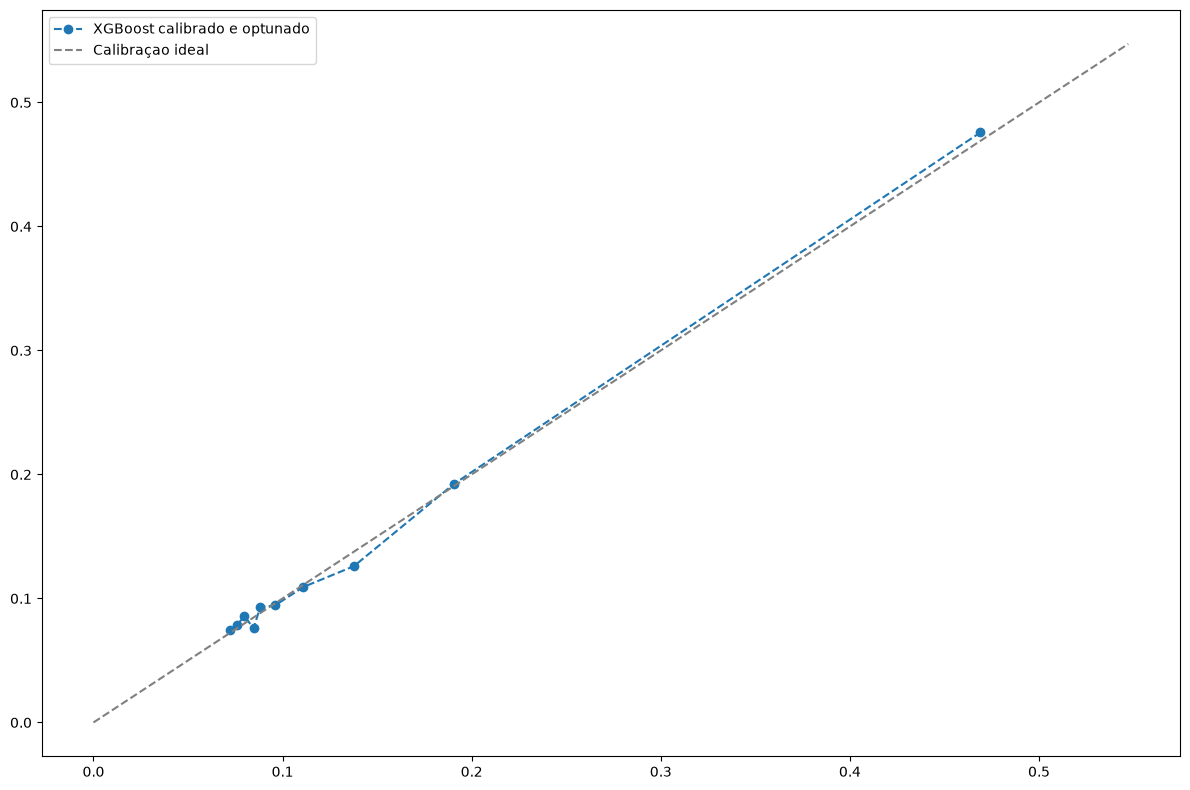

In [35]:
plt.figure(figsize=(12,8))
prob_true_optuna, prob_pred_optuna = calibration_curve(y_test, cal_optuna_pred, n_bins=10, strategy='quantile')
lim = max(prob_pred_optuna.max(), prob_true_optuna.max()) * 1.15
plt.plot(prob_pred_optuna, prob_true_optuna, label='XGBoost calibrado e optunado', linestyle='--', marker='o')
plt.plot([0, lim], [0, lim], linestyle='--', color='gray', label='Calibraçao ideal')
plt.tight_layout()
plt.legend()
plt.show()

# SHAP Values 

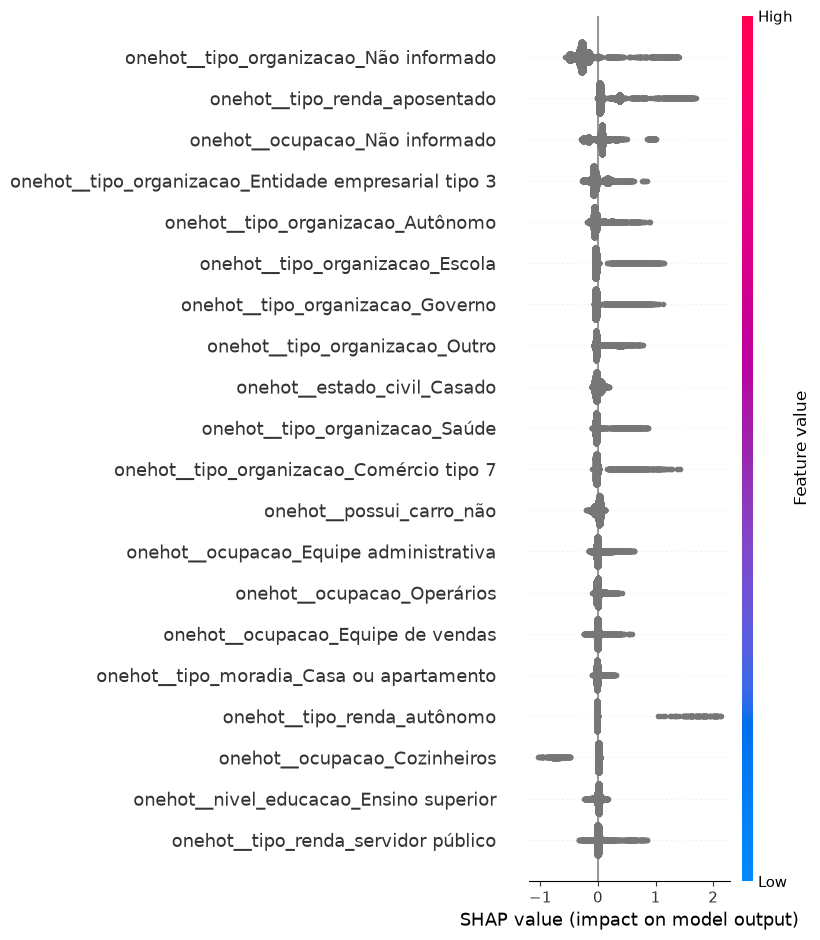

In [55]:
# usando pipe interno
pipe_interno = Xgboost_optuna_cal.calibrated_classifiers_[0].estimator
prep = pipe_interno[:-1]         
model_exp = pipe_interno[-1]      
X_trans = prep.transform(X_test)
feature_names = prep.get_feature_names_out()
explainer = shap.TreeExplainer(model_exp)
shap_values = explainer.shap_values(X_trans)
shap.summary_plot(shap_values, X_trans, feature_names=feature_names)

In [36]:
# exportando o modelo 
model_path = os.path.join('..',  'XGBoost.pkl')
joblib.dump(Xgboost_optuna_cal, model_path)

['..\\XGBoost.pkl']

# Esteira de Crédito 

Para aprovação e reprovação automática dos clientes, irei desenvolver uma esteira de crédito para isso, onde farei uso da politica de crédito de capacidade de pagamento.

As variáveis pensadas para a modelagem da esteira serão: Valor bem/crédito, renda anual e renda per capta